# Customer Churn & Retention Analytics
## 02 – Exploratory Data Analysis (EDA)

### Objective
To explore the cleaned Telco Customer Churn dataset, identify patterns and relationships between customer characteristics and churn behaviour, and discover the major factors contributing to customer attrition.

In [909]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load cleaned dataset
df = pd.read_csv("../Telco-Customer-Churn-Cleaned.csv")

# Display first five rows
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TenureGroup,ChurnFlag
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0-12 Months,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,...,No,No,One year,No,Mailed check,56.95,1889.50,No,25-36 Months,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,0-12 Months,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,37-48 Months,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,0-12 Months,1


In [910]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (7032, 22)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7032 entries, 0 to 7031
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7032 non-null   object 
 1   SeniorCitizen     7032 non-null   int64  
 2   Partner           7032 non-null   object 
 3   Dependents        7032 non-null   object 
 4   tenure            7032 non-null   int64  
 5   PhoneService      7032 non-null   object 
 6   MultipleLines     7032 non-null   object 
 7   InternetService   7032 non-null   object 
 8   OnlineSecurity    7032 non-null   object 
 9   OnlineBackup      7032 non-null   object 
 10  DeviceProtection  7032 non-null   object 
 11  TechSupport       7032 non-null   object 
 12  StreamingTV       7032 non-null   object 
 13  StreamingMovies   7032 non-null   object 
 14  Contract          7032 non-null   object 
 15  PaperlessBilling  7032 non-null   object 

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,ChurnFlag
count,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000
mean,0.162400,32.421786,64.798208,2283.300441,0.265785
std,0.368844,24.545260,30.085974,2266.771362,0.441782
min,0.000000,1.000000,18.250000,18.800000,0.000000
25%,0.000000,9.000000,35.587500,401.450000,0.000000
50%,0.000000,29.000000,70.350000,1397.475000,0.000000
75%,0.000000,55.000000,89.862500,3794.737500,1.000000
max,1.000000,72.000000,118.750000,8684.800000,1.000000


### 2.1 Customer Churn Distribution

This analysis examines the distribution of customers who have discontinued their services compared to those who continue using the telecom services. It helps understand the overall customer churn rate.

In [911]:
# Count customers in each churn category
churn_counts = df['Churn'].value_counts()

print("Customer Churn Distribution:")
print(churn_counts)

# Calculate percentage
churn_percentage = df['Churn'].value_counts(normalize=True) * 100

print("\nChurn Percentage:")
print(churn_percentage.round(2))

Customer Churn Distribution:
Churn
No     5163
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.42
Yes    26.58
Name: proportion, dtype: float64


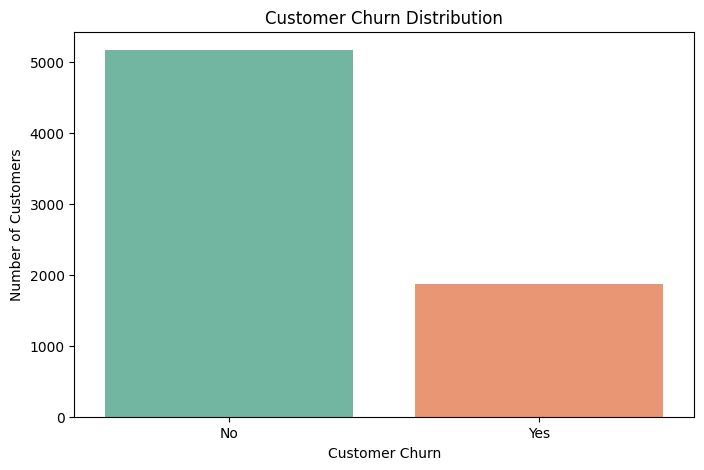

In [912]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Churn', hue='Churn', palette='Set2', legend=False)

plt.title('Customer Churn Distribution')
plt.xlabel('Customer Churn')
plt.ylabel('Number of Customers')

plt.show()

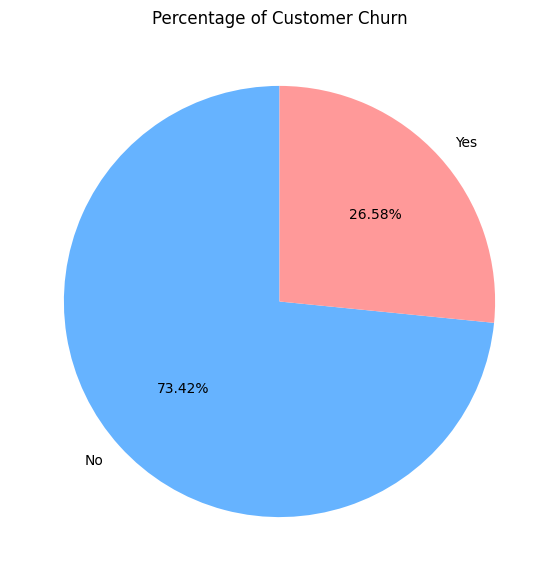

In [913]:
plt.figure(figsize=(7, 7))

plt.pie(
    churn_counts,
    labels=churn_counts.index,
    autopct='%1.2f%%',
    startangle=90,
    colors=['#66b3ff', '#ff9999']
)

plt.title('Percentage of Customer Churn')
plt.show()

### 2.2 Gender-Based Customer Churn Analysis

This analysis examines customer churn across different gender groups to identify whether gender has a noticeable relationship with customer attrition.

In [914]:
# Gender-wise churn count
gender_churn = pd.crosstab(
    df['gender'],
    df['Churn']
)

display(gender_churn)

# Gender-wise churn percentage
gender_churn_rate = pd.crosstab(
    df['gender'],
    df['Churn'],
    normalize='index'
) * 100

display(gender_churn_rate.round(2))

Churn,No,Yes
gender,,
Female,2544,939
Male,2619,930


Churn,No,Yes
gender,,
Female,73.04,26.96
Male,73.80,26.20


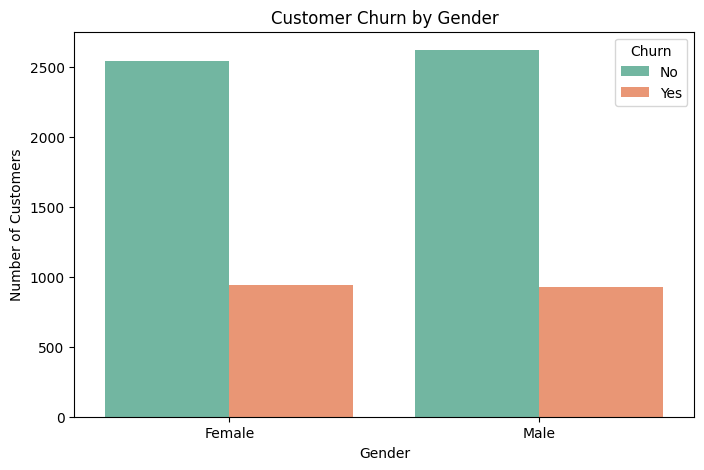

In [915]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='gender',
    hue='Churn',
    palette='Set2'
)

plt.title('Customer Churn by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')
plt.legend(title='Churn')

plt.show()

### 2.3 Senior Citizen-Based Customer Churn Analysis

This analysis investigates the relationship between senior citizen status and customer churn. It compares churn rates between senior and non-senior customers to identify differences in customer retention.

In [916]:
senior_churn = pd.crosstab(
    df['SeniorCitizen'],
    df['Churn']
)

print("Senior Citizen Churn Count:")
display(senior_churn)

senior_churn_rate = pd.crosstab(
    df['SeniorCitizen'],
    df['Churn'],
    normalize='index'
) * 100

print("Senior Citizen Churn Percentage:")
display(senior_churn_rate.round(2))

Senior Citizen Churn Count:


Churn,No,Yes
SeniorCitizen,,
0,4497,1393
1,666,476


Senior Citizen Churn Percentage:


Churn,No,Yes
SeniorCitizen,,
0,76.35,23.65
1,58.32,41.68


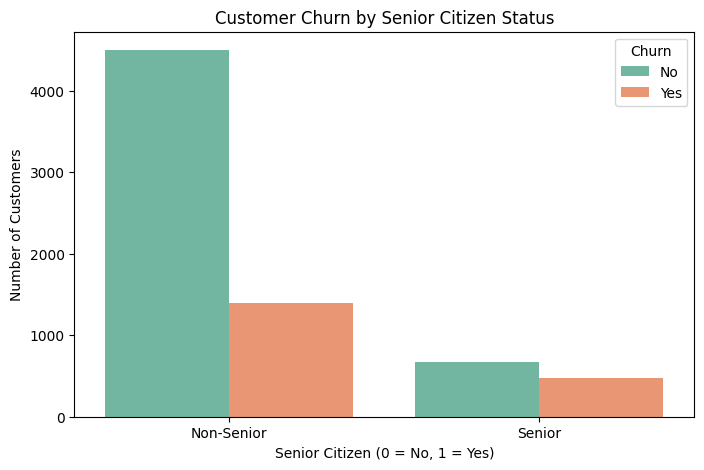

In [917]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='SeniorCitizen',
    hue='Churn',
    palette='Set2'
)

plt.title('Customer Churn by Senior Citizen Status')
plt.xlabel('Senior Citizen (0 = No, 1 = Yes)')
plt.ylabel('Number of Customers')
plt.xticks([0, 1], ['Non-Senior', 'Senior'])
plt.legend(title='Churn')

plt.show()

### 2.4 Partner-Based Customer Churn Analysis

This analysis examines the relationship between customer partner status and churn behaviour. It compares customers who have partners with those who do not to identify differences in customer retention rates.

In [918]:
partner_churn = pd.crosstab(
    df['Partner'],
    df['Churn']
)

print("Partner-Based Churn Count:")
display(partner_churn)

partner_churn_rate = pd.crosstab(
    df['Partner'],
    df['Churn'],
    normalize='index'
) * 100

print("Partner-Based Churn Percentage:")
display(partner_churn_rate.round(2))

Partner-Based Churn Count:


Churn,No,Yes
Partner,,
No,2439,1200
Yes,2724,669


Partner-Based Churn Percentage:


Churn,No,Yes
Partner,,
No,67.02,32.98
Yes,80.28,19.72


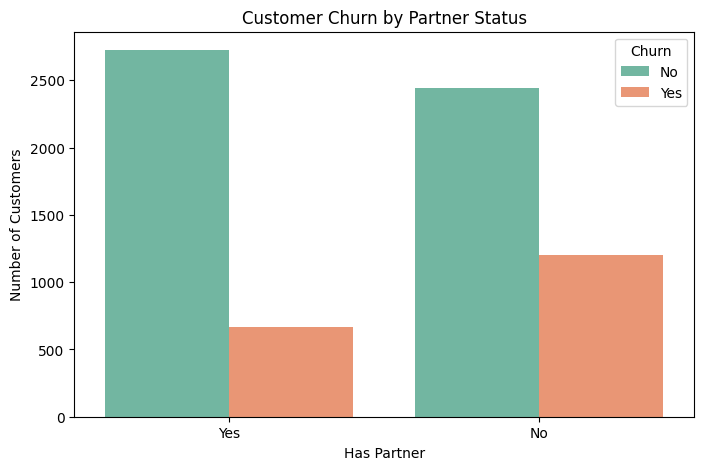

In [919]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Partner',
    hue='Churn',
    palette='Set2'
)

plt.title('Customer Churn by Partner Status')
plt.xlabel('Has Partner')
plt.ylabel('Number of Customers')
plt.legend(title='Churn')

plt.show()

### 2.5 Dependents-Based Customer Churn Analysis

This analysis examines the relationship between customer dependents and churn behaviour. It compares customers with dependents and those without dependents to identify differences in customer retention rates.

In [920]:
dependents_churn = pd.crosstab(
    df['Dependents'],
    df['Churn']
)

print("Dependents-Based Churn Count:")
display(dependents_churn)

dependents_churn_rate = pd.crosstab(
    df['Dependents'],
    df['Churn'],
    normalize='index'
) * 100

print("Dependents-Based Churn Percentage:")
display(dependents_churn_rate.round(2))

Dependents-Based Churn Count:


Churn,No,Yes
Dependents,,
No,3390,1543
Yes,1773,326


Dependents-Based Churn Percentage:


Churn,No,Yes
Dependents,,
No,68.72,31.28
Yes,84.47,15.53


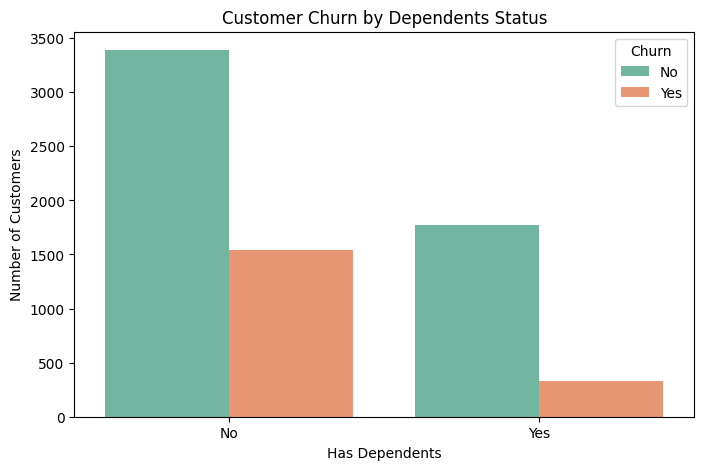

In [921]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Dependents',
    hue='Churn',
    palette='Set2'
)

plt.title('Customer Churn by Dependents Status')
plt.xlabel('Has Dependents')
plt.ylabel('Number of Customers')
plt.legend(title='Churn')

plt.show()

### 2.6 Phone Service-Based Customer Churn Analysis

This analysis examines the relationship between phone service subscriptions and customer churn. It compares customers who have phone services with those who do not, identifying differences in customer retention behaviour.

In [922]:
phone_churn = pd.crosstab(
    df['PhoneService'],
    df['Churn']
)

print("Phone Service-Based Churn Count:")
display(phone_churn)

phone_churn_rate = pd.crosstab(
    df['PhoneService'],
    df['Churn'],
    normalize='index'
) * 100

print("Phone Service-Based Churn Percentage:")
display(phone_churn_rate.round(2))

Phone Service-Based Churn Count:


Churn,No,Yes
PhoneService,,
No,510,170
Yes,4653,1699


Phone Service-Based Churn Percentage:


Churn,No,Yes
PhoneService,,
No,75.00,25.00
Yes,73.25,26.75


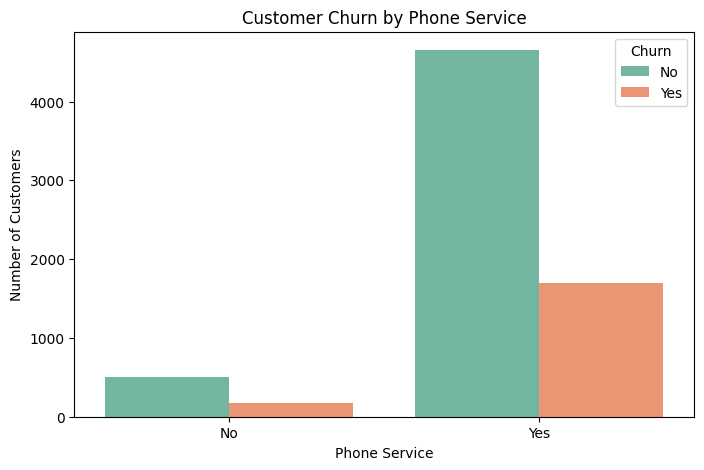

In [923]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='PhoneService',
    hue='Churn',
    palette='Set2'
)

plt.title('Customer Churn by Phone Service')
plt.xlabel('Phone Service')
plt.ylabel('Number of Customers')
plt.legend(title='Churn')

plt.show()

### 2.7 Multiple Lines-Based Customer Churn Analysis

This analysis examines the relationship between multiple-line phone subscriptions and customer churn. It identifies whether customers using multiple phone lines demonstrate different customer retention patterns compared to those using a single phone line or no phone service.

In [924]:
multiple_churn = pd.crosstab(
    df['MultipleLines'],
    df['Churn']
)

print("Multiple Lines-Based Churn Count:")
display(multiple_churn)

multiple_churn_rate = pd.crosstab(
    df['MultipleLines'],
    df['Churn'],
    normalize='index'
) * 100

print("Multiple Lines-Based Churn Percentage:")
display(multiple_churn_rate.round(2))

Multiple Lines-Based Churn Count:


Churn,No,Yes
MultipleLines,,
No,2536,849
No phone service,510,170
Yes,2117,850


Multiple Lines-Based Churn Percentage:


Churn,No,Yes
MultipleLines,,
No,74.92,25.08
No phone service,75.00,25.00
Yes,71.35,28.65


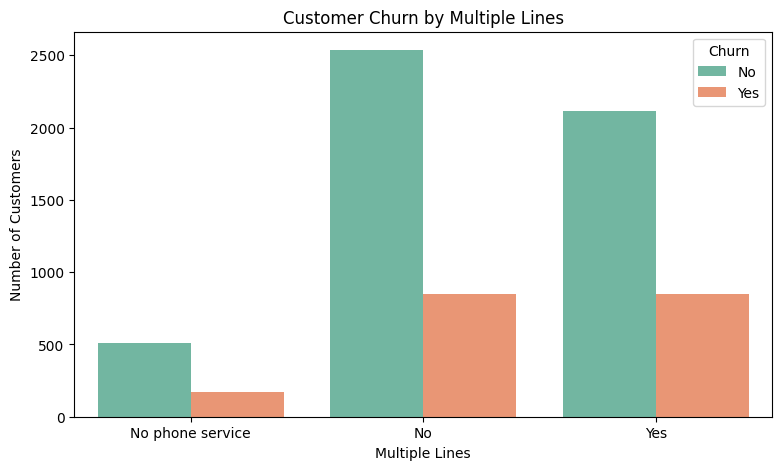

In [925]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='MultipleLines',
    hue='Churn',
    palette='Set2'
)

plt.title('Customer Churn by Multiple Lines')
plt.xlabel('Multiple Lines')
plt.ylabel('Number of Customers')
plt.legend(title='Churn')

plt.show()

### 2.8 Internet Service-Based Customer Churn Analysis

This analysis examines the relationship between internet service subscriptions and customer churn. It compares churn behaviour among customers using DSL, Fiber Optic, and customers without internet service to identify which internet service category experiences the highest customer churn.

In [926]:
internet_churn = pd.crosstab(
    df['InternetService'],
    df['Churn']
)

print("Internet Service-Based Churn Count:")
display(internet_churn)

internet_churn_rate = pd.crosstab(
    df['InternetService'],
    df['Churn'],
    normalize='index'
) * 100

print("Internet Service-Based Churn Percentage:")
display(internet_churn_rate.round(2))

Internet Service-Based Churn Count:


Churn,No,Yes
InternetService,,
DSL,1957,459
Fiber optic,1799,1297
No,1407,113


Internet Service-Based Churn Percentage:


Churn,No,Yes
InternetService,,
DSL,81.00,19.00
Fiber optic,58.11,41.89
No,92.57,7.43


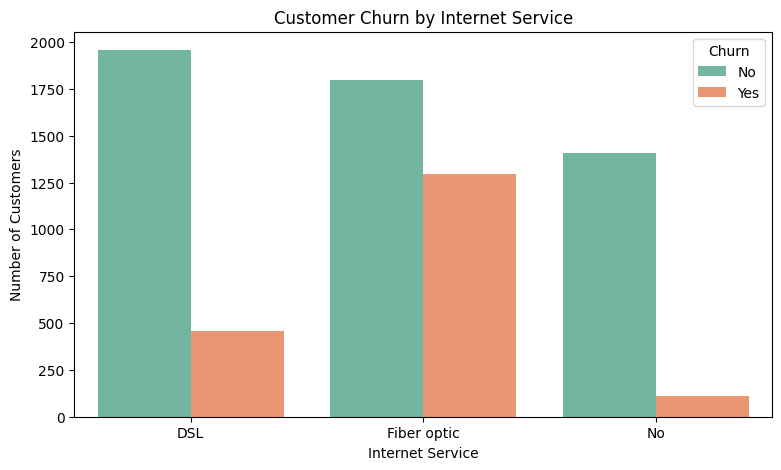

In [927]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='InternetService',
    hue='Churn',
    palette='Set2'
)

plt.title('Customer Churn by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Number of Customers')
plt.legend(title='Churn')

plt.show()

### 2.9 Online Security-Based Customer Churn Analysis

This analysis examines the relationship between online security subscriptions and customer churn. It compares customers who have online security services with those who do not, identifying whether online security subscription status influences customer retention behaviour.

In [928]:
security_churn = pd.crosstab(
    df['OnlineSecurity'],
    df['Churn']
)

print("Online Security-Based Churn Count:")
display(security_churn)

security_churn_rate = pd.crosstab(
    df['OnlineSecurity'],
    df['Churn'],
    normalize='index'
) * 100

print("Online Security-Based Churn Percentage:")
display(security_churn_rate.round(2))

Online Security-Based Churn Count:


Churn,No,Yes
OnlineSecurity,,
No,2036,1461
No internet service,1407,113
Yes,1720,295


Online Security-Based Churn Percentage:


Churn,No,Yes
OnlineSecurity,,
No,58.22,41.78
No internet service,92.57,7.43
Yes,85.36,14.64


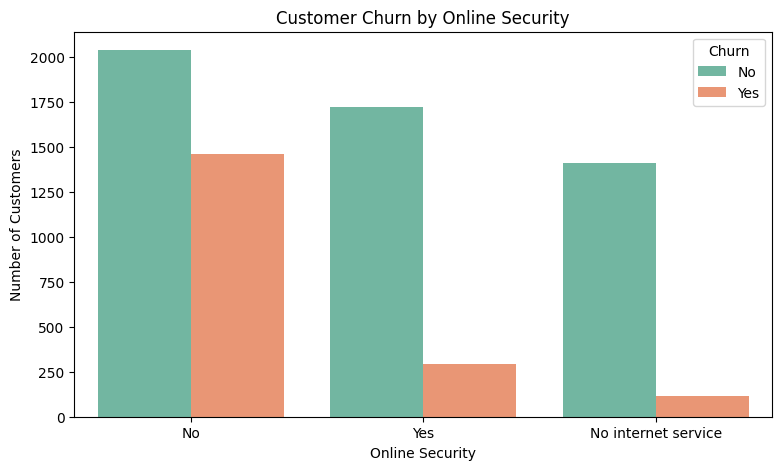

In [929]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='OnlineSecurity',
    hue='Churn',
    palette='Set2'
)

plt.title('Customer Churn by Online Security')
plt.xlabel('Online Security')
plt.ylabel('Number of Customers')
plt.legend(title='Churn')

plt.show()

### 2.10 Online Backup-Based Customer Churn Analysis

This analysis examines the relationship between online backup subscriptions and customer churn. It compares customers who subscribe to online backup services with those who do not, identifying differences in customer retention behaviour.

In [930]:
backup_churn = pd.crosstab(
    df['OnlineBackup'],
    df['Churn']
)

print("Online Backup-Based Churn Count:")
display(backup_churn)

backup_churn_rate = pd.crosstab(
    df['OnlineBackup'],
    df['Churn'],
    normalize='index'
) * 100

print("Online Backup-Based Churn Percentage:")
display(backup_churn_rate.round(2))

Online Backup-Based Churn Count:


Churn,No,Yes
OnlineBackup,,
No,1854,1233
No internet service,1407,113
Yes,1902,523


Online Backup-Based Churn Percentage:


Churn,No,Yes
OnlineBackup,,
No,60.06,39.94
No internet service,92.57,7.43
Yes,78.43,21.57


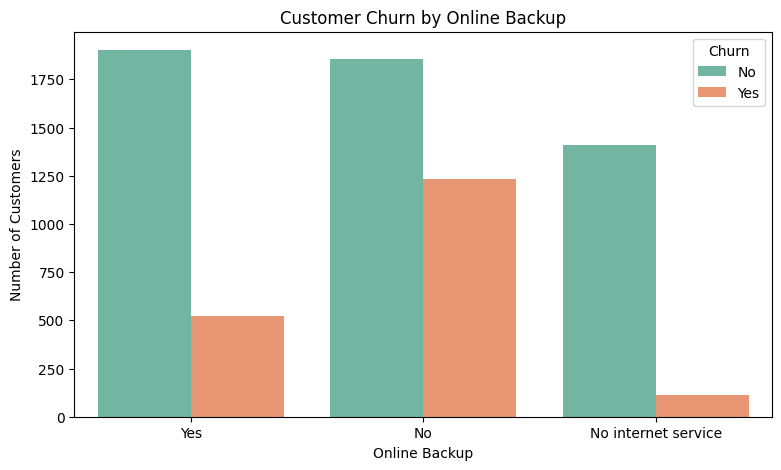

In [931]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='OnlineBackup',
    hue='Churn',
    palette='Set2'
)

plt.title('Customer Churn by Online Backup')
plt.xlabel('Online Backup')
plt.ylabel('Number of Customers')
plt.legend(title='Churn')

plt.show()

### 2.11 Device Protection-Based Customer Churn Analysis

This analysis examines the relationship between device protection subscriptions and customer churn. It compares customers who subscribe to device protection services with those who do not, identifying differences in customer retention behaviour.

In [932]:
device_churn = pd.crosstab(
    df['DeviceProtection'],
    df['Churn']
)

print("Device Protection-Based Churn Count:")
display(device_churn)

device_churn_rate = pd.crosstab(
    df['DeviceProtection'],
    df['Churn'],
    normalize='index'
) * 100

print("Device Protection-Based Churn Percentage:")
display(device_churn_rate.round(2))

Device Protection-Based Churn Count:


Churn,No,Yes
DeviceProtection,,
No,1883,1211
No internet service,1407,113
Yes,1873,545


Device Protection-Based Churn Percentage:


Churn,No,Yes
DeviceProtection,,
No,60.86,39.14
No internet service,92.57,7.43
Yes,77.46,22.54


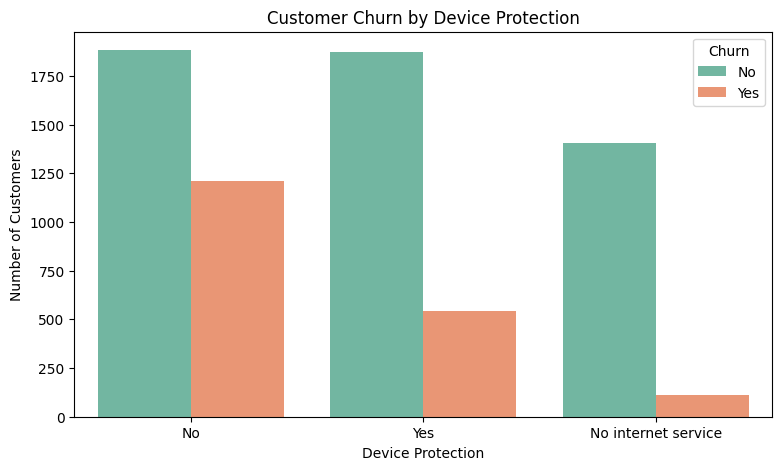

In [933]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='DeviceProtection',
    hue='Churn',
    palette='Set2'
)

plt.title('Customer Churn by Device Protection')
plt.xlabel('Device Protection')
plt.ylabel('Number of Customers')
plt.legend(title='Churn')

plt.show()

### 2.12 Tech Support-Based Customer Churn Analysis

This analysis examines the relationship between technical support subscriptions and customer churn. It compares customers who subscribe to technical support services with those who do not, helping identify whether technical support availability influences customer retention.

In [934]:
tech_churn = pd.crosstab(
    df['TechSupport'],
    df['Churn']
)

print("Tech Support-Based Churn Count:")
display(tech_churn)

tech_churn_rate = pd.crosstab(
    df['TechSupport'],
    df['Churn'],
    normalize='index'
) * 100

print("Tech Support-Based Churn Percentage:")
display(tech_churn_rate.round(2))

Tech Support-Based Churn Count:


Churn,No,Yes
TechSupport,,
No,2026,1446
No internet service,1407,113
Yes,1730,310


Tech Support-Based Churn Percentage:


Churn,No,Yes
TechSupport,,
No,58.35,41.65
No internet service,92.57,7.43
Yes,84.80,15.20


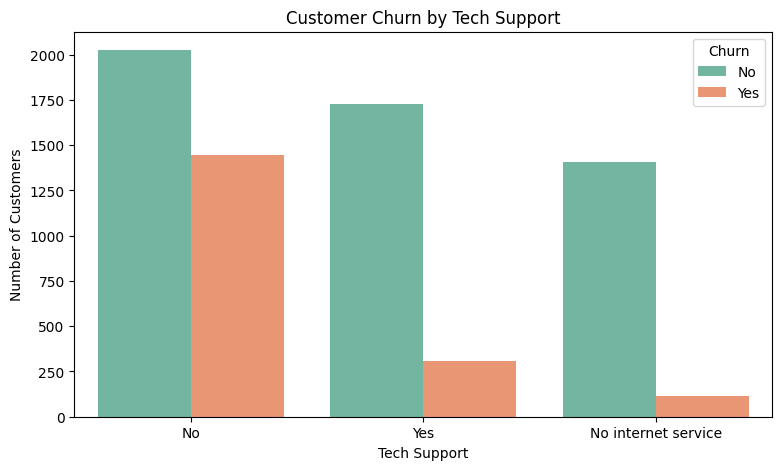

In [935]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='TechSupport',
    hue='Churn',
    palette='Set2'
)

plt.title('Customer Churn by Tech Support')
plt.xlabel('Tech Support')
plt.ylabel('Number of Customers')
plt.legend(title='Churn')

plt.show()

### 2.13 Streaming TV-Based Customer Churn Analysis

This analysis examines the relationship between Streaming TV subscriptions and customer churn. It compares churn rates among customers who subscribe to Streaming TV, those who do not, and those without internet service to understand its influence on customer retention.

In [936]:
streaming_tv_churn = pd.crosstab(
    df['StreamingTV'],
    df['Churn']
)

print("Streaming TV-Based Churn Count:")
display(streaming_tv_churn)

streaming_tv_rate = pd.crosstab(
    df['StreamingTV'],
    df['Churn'],
    normalize='index'
) * 100

print("Streaming TV-Based Churn Percentage:")
display(streaming_tv_rate.round(2))

Streaming TV-Based Churn Count:


Churn,No,Yes
StreamingTV,,
No,1867,942
No internet service,1407,113
Yes,1889,814


Streaming TV-Based Churn Percentage:


Churn,No,Yes
StreamingTV,,
No,66.46,33.54
No internet service,92.57,7.43
Yes,69.89,30.11


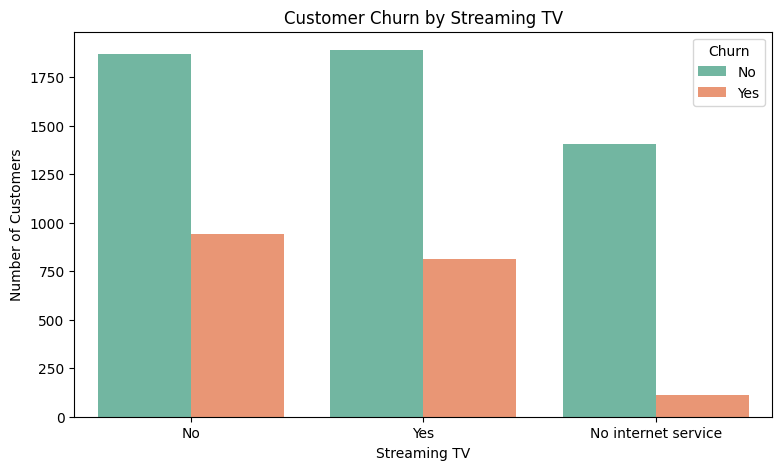

In [937]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='StreamingTV',
    hue='Churn',
    palette='Set2'
)

plt.title('Customer Churn by Streaming TV')
plt.xlabel('Streaming TV')
plt.ylabel('Number of Customers')
plt.legend(title='Churn')

plt.show()

### 2.14 Streaming Movies-Based Customer Churn Analysis

This analysis examines the relationship between Streaming Movies subscriptions and customer churn. It compares the churn rates of customers who subscribe to Streaming Movies, those who do not, and customers without internet service to understand its relationship with customer retention.

In [938]:
movies_churn = pd.crosstab(
    df['StreamingMovies'],
    df['Churn']
)

print("Streaming Movies-Based Churn Count:")
display(movies_churn)

movies_rate = pd.crosstab(
    df['StreamingMovies'],
    df['Churn'],
    normalize='index'
) * 100

print("Streaming Movies-Based Churn Percentage:")
display(movies_rate.round(2))

Streaming Movies-Based Churn Count:


Churn,No,Yes
StreamingMovies,,
No,1843,938
No internet service,1407,113
Yes,1913,818


Streaming Movies-Based Churn Percentage:


Churn,No,Yes
StreamingMovies,,
No,66.27,33.73
No internet service,92.57,7.43
Yes,70.05,29.95


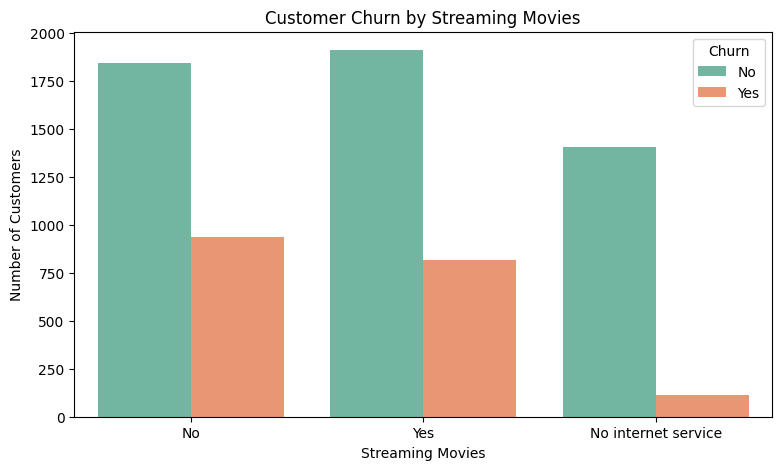

In [939]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='StreamingMovies',
    hue='Churn',
    palette='Set2'
)

plt.title('Customer Churn by Streaming Movies')
plt.xlabel('Streaming Movies')
plt.ylabel('Number of Customers')
plt.legend(title='Churn')

plt.show()

### 2.15 Contract-Based Customer Churn Analysis

This analysis examines the relationship between customer contract types and churn. It compares Month-to-month, One-year and Two-year contract customers to identify which contract category experiences the highest churn rate and understand how contract duration influences customer retention.

In [940]:
contract_churn = pd.crosstab(
    df['Contract'],
    df['Churn']
)

print("Contract-Based Churn Count:")
display(contract_churn)

contract_rate = pd.crosstab(
    df['Contract'],
    df['Churn'],
    normalize='index'
) * 100

print("Contract-Based Churn Percentage:")
display(contract_rate.round(2))

Contract-Based Churn Count:


Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1306,166
Two year,1637,48


Contract-Based Churn Percentage:


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.72,11.28
Two year,97.15,2.85


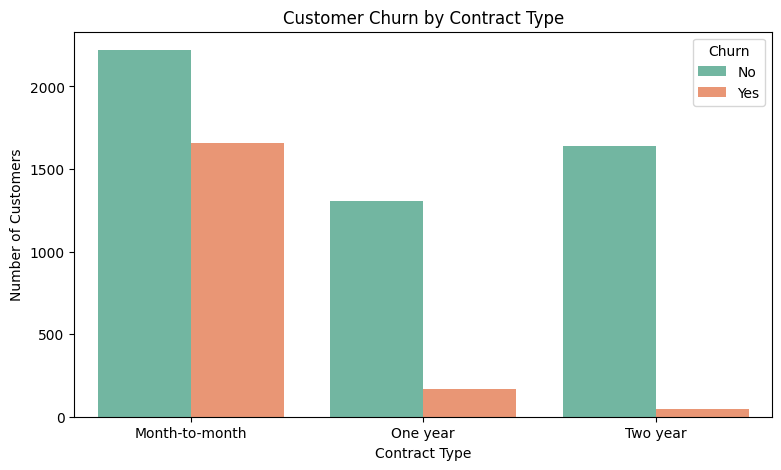

In [941]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='Contract',
    hue='Churn',
    palette='Set2',
    order=['Month-to-month', 'One year', 'Two year']
)

plt.title('Customer Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.legend(title='Churn')

plt.show()

### 2.16 Paperless Billing-Based Customer Churn Analysis

This analysis examines the relationship between paperless billing and customer churn. It compares customers who use paperless billing with those who receive traditional paper bills to understand whether billing preferences are associated with customer retention.

In [942]:
billing_churn = pd.crosstab(
    df['PaperlessBilling'],
    df['Churn']
)

print("Paperless Billing-Based Churn Count:")
display(billing_churn)

billing_rate = pd.crosstab(
    df['PaperlessBilling'],
    df['Churn'],
    normalize='index'
) * 100

print("Paperless Billing-Based Churn Percentage:")
display(billing_rate.round(2))

Paperless Billing-Based Churn Count:


Churn,No,Yes
PaperlessBilling,,
No,2395,469
Yes,2768,1400


Paperless Billing-Based Churn Percentage:


Churn,No,Yes
PaperlessBilling,,
No,83.62,16.38
Yes,66.41,33.59


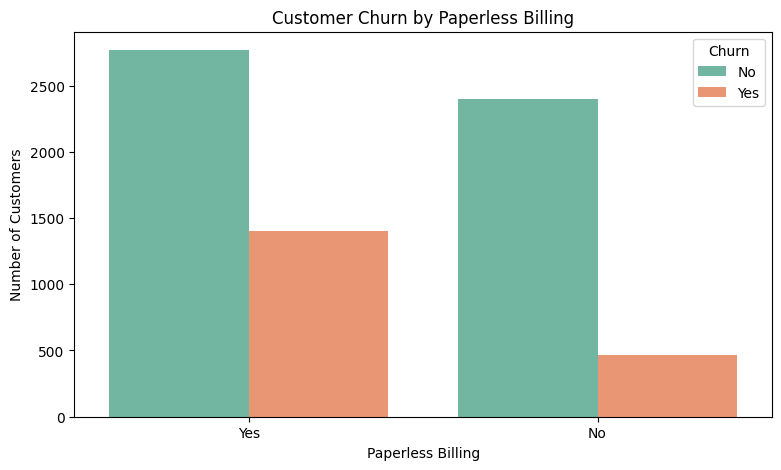

In [943]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='PaperlessBilling',
    hue='Churn',
    palette='Set2'
)

plt.title('Customer Churn by Paperless Billing')
plt.xlabel('Paperless Billing')
plt.ylabel('Number of Customers')
plt.legend(title='Churn')

plt.show()